In [1]:
import pandas as pd
import numpy as np
import random
import time
import pickle
import os
import sys

sys.path.append(os.path.abspath('..'))

from sklearn.model_selection import StratifiedKFold
from sklearn import tree
from IPython.display import display

from utils.graphs import plot_confusion_matrix
from utils.util import evaluate_predictions, cross_evaluate_stratified_group
from utils.models import available_models, get_model


print("Pandas version: {}".format(pd.__version__))
print("NumPy version: {}".format(np.__version__))

seed = 42
np.random.seed(seed)
random.seed(seed)

Pandas version: 2.2.2
NumPy version: 2.0.1


# Load the data

In [2]:
df = pd.read_parquet("../../data/CICIDS2017_improved/clean/tuesday-latest.parquet")
# Drop spurious features for 2017 dataset
df = df.drop(columns=['FWD Init Win Bytes', 'Bwd Init Win Bytes'])

adv_files = [
    "patator-ssh-cic.parquet",
    "patator-versions-ssh-cic.parquet",
    "patator-network-ssh-cic.parquet",
    "hydra-ssh-cic.parquet",
    "medusa-ssh-cic.parquet",
]
df_adv = pd.concat([pd.read_parquet(f"../../data/concap/clean/{f}") for f in adv_files], ignore_index=True)
# Drop spurious features from 2017 dataset
df_adv = df_adv.drop(columns=['FWD Init Win Bytes', 'Bwd Init Win Bytes'])

df_adv.scenario.value_counts()

scenario
patator_ssh_cic_T5                     3400
patator_ssh_cic_T10                    3400
patator_ssh_cic_T1                     3400
medusa_ssh_cic_ubuntu24_T10_default    1151
medusa_ssh_cic_ubuntu24_T10_long       1151
medusa_ssh_cic_ubuntu20_T10_long       1149
medusa_ssh_cic_ubuntu18_T10_long       1149
medusa_ssh_cic_ubuntu20_T10_min        1148
medusa_ssh_cic_ubuntu20_T10_default    1148
medusa_ssh_cic_ubuntu18_T10_default    1147
medusa_ssh_cic_ubuntu18_T10_min        1147
medusa_ssh_cic_ubuntu24_T10_min        1145
hydra_ssh_cic_ubuntu20_T10              758
hydra_ssh_cic_ubuntu24_T10              755
hydra_ssh_cic_ubuntu18_T10              727
patator_ssh_cic_D10_L0_C0_Dup0          680
patator_ssh_cic_D25_L5_C5_Dup5          680
patator_ssh_cic_D100_L0_C5_Dup5         680
patator_ssh_cic_D10_L5_C0_Dup5          680
patator_ssh_cic_D10_L5_C0_Dup0          680
patator_ssh_cic_D25_L0_C5_Dup0          680
patator_ssh_cic_D100_L5_C0_Dup0         680
patator_ssh_cic_D100_L5

# Prepare for Evaluation

In [3]:
result_dir = "../results/cicids2017-latest/generalisation"
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

In [4]:
train_scenarios = [ # train on scenarios with single and 10 threads, test on 5 threads.
    'patator-ssh-cic-t1',
    'patator-ssh-cic-t10',
    # 'patator-ssh-cic-t5',
    'patator-ssh-cic-t10-p-rl1',
    'patator-ssh-cic-t10-p',
    # 'patator-ssh-cic-t5-p',
    # 'patator-ssh-cic-t5-p-rl1',
    'patator-ssh-cic-t1-p',
    'patator-ssh-cic-t1-p-rl1'
]
df_adv['scenario'] = df_adv.scenario.map(lambda x: x.replace("_", "-").lower())
X_adv, y_adv, groups = df_adv.drop(columns=["Label", "scenario"]), pd.Series(np.ones(df_adv.shape[0])), df_adv["scenario"]
X_adv_train, y_adv_train, groups_train = X_adv[df_adv.scenario.isin(train_scenarios)], y_adv[df_adv.scenario.isin(train_scenarios)], groups[df_adv.scenario.isin(train_scenarios)]
X_adv_test, y_adv_test, groups_test = X_adv[~df_adv.scenario.isin(train_scenarios)], y_adv[~df_adv.scenario.isin(train_scenarios)], groups[~df_adv.scenario.isin(train_scenarios)]

In [5]:
X, y = df.drop(columns=["Label"]), df["Label"].map(lambda x: 0 if x == "BENIGN" else 1)
X_benign, y_benign = X[y == 0], y[y == 0]
X_mal, y_mal = X[df["Label"] == 'SSH-Patator'], y[df["Label"] == 'SSH-Patator'] # only use SSH-Patator

In [6]:
X, y, groups = pd.concat([X_benign, X_adv_train]), pd.Series(np.concatenate([y_benign, y_adv_train])), pd.concat([df.loc[y == 0, 'Label'], groups_train])
groups.value_counts()

BENIGN                       302280
patator-ssh-cic-t10            3400
patator-ssh-cic-t1             3400
patator-ssh-cic-t10-p-rl1       680
patator-ssh-cic-t10-p           680
patator-ssh-cic-t1-p            578
patator-ssh-cic-t1-p-rl1        578
Name: count, dtype: int64

# Model Training

The models get trained on the benign samples from the dataset combined with attacks generated by concap. The models are then evaluated on unseen concap scenarios, and the original malicious samples from the dataset.

Evaluating model: decision_tree


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,4.956795,0.101144,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.028656,0.999732,1.000000,0.999464,0.999984,0.999983,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60455, 1], [0, 1864]]"
1,6.071674,0.098611,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.029917,0.999732,1.000000,0.999464,0.999984,0.999983,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60455, 1], [0, 1863]]"
2,4.884548,0.099866,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.027634,0.999732,1.000000,0.999464,0.999984,0.999983,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60455, 1], [0, 1863]]"
3,4.796485,0.100725,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.028760,0.999463,0.999463,0.999463,0.999968,0.999983,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60455, 1], [1, 1862]]"
4,5.839486,0.100194,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.026645,1.000000,1.000000,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,5.309798,0.100108,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.028323,0.999732,0.999893,0.999571,0.999984,0.999987,NaN,62319.200000,NaN
std,0.597905,0.000970,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.001238,0.000190,0.000240,0.000240,0.000011,0.000007,NaN,0.447214,NaN


Aggregated test confusion matrix:


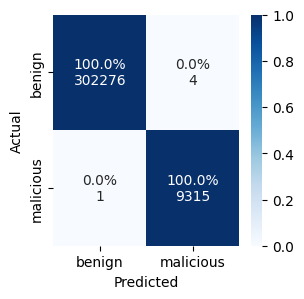

Training time for on all data: 5.2793

Evaluating model: decision_tree_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,5.074958,0.153104,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.041351,1.000000,1.000000,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60456, 0], [0, 1864]]"
1,5.516158,0.150951,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.040748,1.000000,1.000000,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,6.397211,0.160427,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.043538,0.999195,1.000000,0.998392,0.999952,0.999950,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60453, 3], [0, 1863]]"
3,6.315274,0.159922,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.043033,0.999195,0.999463,0.998927,0.999952,0.999967,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60454, 2], [1, 1862]]"
4,5.058113,0.145671,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.039743,1.000000,1.000000,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,5.672343,0.154015,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.041683,0.999678,0.999893,0.999464,0.999981,0.999983,NaN,62319.200000,NaN
std,0.651409,0.006242,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.001582,0.000441,0.000240,0.000758,0.000026,0.000023,NaN,0.447214,NaN


Aggregated test confusion matrix:


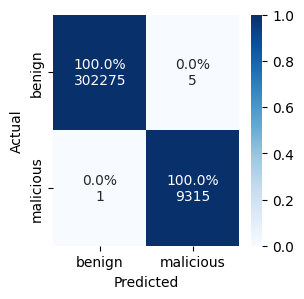

Training time for on all data: 6.1177

Evaluating model: logistic_regression


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,2.960752,0.346482,0.995325,1.0,0.990694,0.999719,0.999711,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241754, 70], [0, 7452]]",0.093694,0.997325,1.0,0.994664,0.999840,0.999835,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60446, 10], [0, 1864]]"
1,4.156947,0.163358,0.996524,1.0,0.993071,0.999791,0.999785,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241772, 52], [0, 7453]]",0.042583,0.996523,1.0,0.993070,0.999791,0.999785,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60443, 13], [0, 1863]]"
2,3.083774,0.223236,0.997057,1.0,0.994131,0.999823,0.999818,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241780, 44], [0, 7453]]",0.048071,0.995458,1.0,0.990957,0.999727,0.999719,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60439, 17], [0, 1863]]"
3,3.444786,0.223457,0.997057,1.0,0.994131,0.999823,0.999818,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241780, 44], [0, 7453]]",0.048758,0.994927,1.0,0.989904,0.999695,0.999686,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60437, 19], [0, 1863]]"
4,2.943041,0.281004,0.995193,1.0,0.990432,0.999711,0.999702,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241752, 72], [0, 7453]]",0.071216,0.997056,1.0,0.994130,0.999823,0.999818,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60445, 11], [0, 1863]]"
mean,3.317860,0.247507,0.996231,1.0,0.992492,0.999774,0.999767,NaN,249276.800000,NaN,0.060865,0.996258,1.0,0.992545,0.999775,0.999768,NaN,62319.200000,NaN
std,0.510634,0.069222,0.000915,0.0,0.001816,0.000055,0.000057,NaN,0.447214,NaN,0.021386,0.001032,0.0,0.002048,0.000062,0.000064,NaN,0.447214,NaN


Aggregated test confusion matrix:


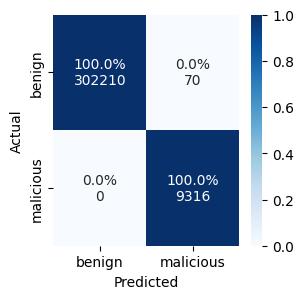

Training time for on all data: 2.4842

Evaluating model: logistic_regression_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,2.219316,0.419266,0.995325,1.0,0.990694,0.999719,0.999711,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241754, 70], [0, 7452]]",0.110211,0.997325,1.0,0.994664,0.999840,0.999835,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60446, 10], [0, 1864]]"
1,3.998286,0.273174,0.996524,1.0,0.993071,0.999791,0.999785,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241772, 52], [0, 7453]]",0.068564,0.996523,1.0,0.993070,0.999791,0.999785,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60443, 13], [0, 1863]]"
2,3.685288,0.324250,0.997057,1.0,0.994131,0.999823,0.999818,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241780, 44], [0, 7453]]",0.061339,0.995458,1.0,0.990957,0.999727,0.999719,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60439, 17], [0, 1863]]"
3,3.303838,0.403090,0.997057,1.0,0.994131,0.999823,0.999818,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241780, 44], [0, 7453]]",0.068207,0.994927,1.0,0.989904,0.999695,0.999686,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60437, 19], [0, 1863]]"
4,2.675244,0.378888,0.995193,1.0,0.990432,0.999711,0.999702,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241752, 72], [0, 7453]]",0.096459,0.997056,1.0,0.994130,0.999823,0.999818,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60445, 11], [0, 1863]]"
mean,3.176394,0.359734,0.996231,1.0,0.992492,0.999774,0.999767,NaN,249276.800000,NaN,0.080956,0.996258,1.0,0.992545,0.999775,0.999768,NaN,62319.200000,NaN
std,0.727646,0.060296,0.000915,0.0,0.001816,0.000055,0.000057,NaN,0.447214,NaN,0.021196,0.001032,0.0,0.002048,0.000062,0.000064,NaN,0.447214,NaN


Aggregated test confusion matrix:


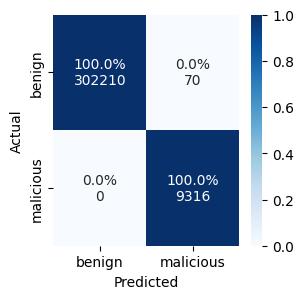

Training time for on all data: 2.4745

Evaluating model: one_rule


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,17.906633,0.082678,0.433017,1.0,0.276338,0.921713,0.919301,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[222309, 19515], [0, 7452]]",0.022763,0.431132,1.0,0.274805,0.921069,0.918635,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[55537, 4919], [0, 1864]]"
1,18.030670,0.066879,0.432597,1.0,0.275996,0.921569,0.919152,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222273, 19551], [0, 7453]]",0.019011,0.432803,1.0,0.276164,0.921645,0.919231,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55573, 4883], [0, 1863]]"
2,25.152632,0.071484,0.432183,1.0,0.275659,0.921437,0.919015,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222240, 19584], [0, 7453]]",0.018919,0.434468,1.0,0.277521,0.922175,0.919776,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55606, 4850], [0, 1863]]"
3,25.018592,0.072056,0.433465,1.0,0.276703,0.921846,0.919437,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222342, 19482], [0, 7453]]",0.019277,0.429362,1.0,0.273368,0.920538,0.918089,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55504, 4952], [0, 1863]]"
4,17.895470,0.076254,0.431933,1.0,0.275456,0.921357,0.918933,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222220, 19604], [0, 7453]]",0.021158,0.435484,1.0,0.278351,0.922496,0.920107,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55626, 4830], [0, 1863]]"
mean,20.800800,0.073870,0.432639,1.0,0.276030,0.921584,0.919168,NaN,249276.800000,NaN,0.020225,0.432650,1.0,0.276042,0.921584,0.919168,NaN,62319.200000,NaN
std,3.912128,0.005940,0.000619,0.0,0.000504,0.000199,0.000206,NaN,0.447214,NaN,0.001688,0.002474,0.0,0.002013,0.000797,0.000822,NaN,0.447214,NaN


Aggregated test confusion matrix:


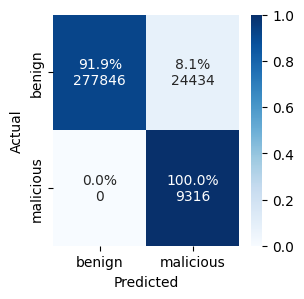

Best feature index: 8
Training time for on all data: 21.7212

Evaluating model: one_rule_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,17.751421,0.122333,0.433017,1.0,0.276338,0.921713,0.919301,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[222309, 19515], [0, 7452]]",0.036103,0.431132,1.0,0.274805,0.921069,0.918635,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[55537, 4919], [0, 1864]]"
1,22.658258,0.112216,0.432597,1.0,0.275996,0.921569,0.919152,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222273, 19551], [0, 7453]]",0.030677,0.432803,1.0,0.276164,0.921645,0.919231,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55573, 4883], [0, 1863]]"
2,18.165171,0.117511,0.432183,1.0,0.275659,0.921437,0.919015,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222240, 19584], [0, 7453]]",0.032852,0.434468,1.0,0.277521,0.922175,0.919776,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55606, 4850], [0, 1863]]"
3,25.043496,0.111108,0.433465,1.0,0.276703,0.921846,0.919437,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222342, 19482], [0, 7453]]",0.031511,0.429362,1.0,0.273368,0.920538,0.918089,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55504, 4952], [0, 1863]]"
4,20.468993,0.112114,0.431933,1.0,0.275456,0.921357,0.918933,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[222220, 19604], [0, 7453]]",0.029998,0.435484,1.0,0.278351,0.922496,0.920107,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[55626, 4830], [0, 1863]]"
mean,20.817468,0.115056,0.432639,1.0,0.276030,0.921584,0.919168,NaN,249276.800000,NaN,0.032228,0.432650,1.0,0.276042,0.921584,0.919168,NaN,62319.200000,NaN
std,3.074271,0.004777,0.000619,0.0,0.000504,0.000199,0.000206,NaN,0.447214,NaN,0.002413,0.002474,0.0,0.002013,0.000797,0.000822,NaN,0.447214,NaN


Aggregated test confusion matrix:


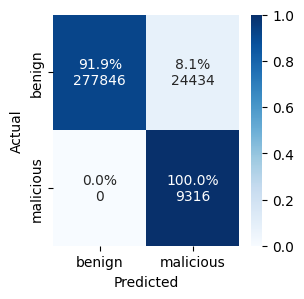

Best feature index: 8
Training time for on all data: 21.4338

Evaluating model: random_forest


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,31.682114,0.419902,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.104205,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60456, 0], [0, 1864]]"
1,38.950666,0.675614,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.178968,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,39.810392,0.556172,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.107346,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
3,39.357215,0.670652,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.174232,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
4,40.273876,0.530973,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.110364,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,38.014853,0.570663,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.135023,1.0,1.0,1.0,1.0,1.0,NaN,62319.200000,NaN
std,3.574507,0.106685,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.038054,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


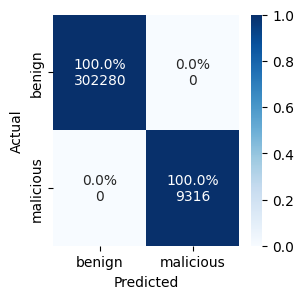

Training time for on all data: 35.5704

Evaluating model: random_forest_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,30.974022,0.460798,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.105416,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60456, 0], [0, 1864]]"
1,40.592588,0.743492,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.120300,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,40.096095,0.680473,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.185923,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
3,39.953707,0.668841,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.194929,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
4,40.138419,0.721207,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.119622,1.0,1.0,1.0,1.0,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,38.350966,0.654962,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.145238,1.0,1.0,1.0,1.0,1.0,NaN,62319.200000,NaN
std,4.130781,0.112660,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.041798,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


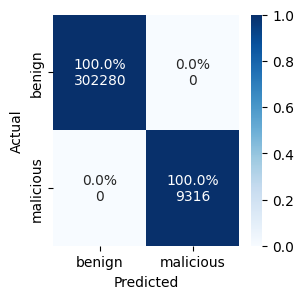

Training time for on all data: 37.7359

Evaluating model: neural_network


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,17.485533,0.540901,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.141198,0.999732,1.0,0.999464,0.999984,0.999983,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60455, 1], [0, 1864]]"
1,21.099701,0.528853,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.128029,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,20.832906,0.537041,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.127801,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
3,20.215194,0.559673,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.160336,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
4,20.515568,0.536209,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.111587,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,20.029780,0.540536,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.133790,0.999946,1.0,0.999893,0.999997,0.999997,NaN,62319.200000,NaN
std,1.460591,0.011552,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.018177,0.000120,0.0,0.000240,0.000007,0.000007,NaN,0.447214,NaN


Aggregated test confusion matrix:


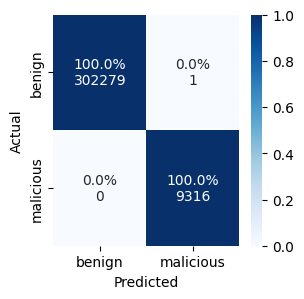

Training time for on all data: 19.7646

Evaluating model: neural_network_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,17.724584,0.658738,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.151979,0.999732,1.0,0.999464,0.999984,0.999983,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60455, 1], [0, 1864]]"
1,17.750992,0.645443,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.155769,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,17.541446,0.626132,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.120911,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
3,17.685523,0.602000,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.130948,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
4,18.046193,0.621712,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.110694,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,17.749748,0.630805,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.134060,0.999946,1.0,0.999893,0.999997,0.999997,NaN,62319.200000,NaN
std,0.184410,0.021959,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.019500,0.000120,0.0,0.000240,0.000007,0.000007,NaN,0.447214,NaN


Aggregated test confusion matrix:


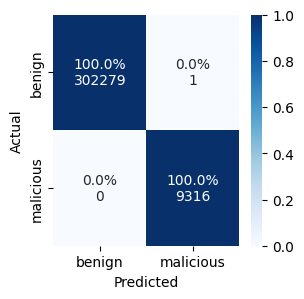

Training time for on all data: 21.2048

Evaluating model: support_vector_machine


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,31.482077,15.793756,0.999062,1.0,0.998125,0.999944,0.999942,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241810, 14], [0, 7452]]",4.008102,0.998928,1.0,0.997859,0.999936,0.999934,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60452, 4], [0, 1864]]"
1,22.211225,17.745001,0.998995,1.0,0.997991,0.999940,0.999938,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241809, 15], [0, 7453]]",4.799495,0.998660,1.0,0.997323,0.999920,0.999917,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60451, 5], [0, 1863]]"
2,19.366616,13.487262,0.999330,1.0,0.998660,0.999960,0.999959,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241814, 10], [0, 7453]]",3.387144,0.998660,1.0,0.997323,0.999920,0.999917,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60451, 5], [0, 1863]]"
3,20.316327,18.819407,0.998861,1.0,0.997724,0.999932,0.999930,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241807, 17], [0, 7453]]",4.216896,0.999195,1.0,0.998392,0.999952,0.999950,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60453, 3], [0, 1863]]"
4,33.196946,19.526510,0.998861,1.0,0.997724,0.999932,0.999930,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241807, 17], [0, 7453]]",4.424726,0.999464,1.0,0.998928,0.999968,0.999967,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60454, 2], [0, 1863]]"
mean,25.314638,17.074387,0.999021,1.0,0.998045,0.999941,0.999940,NaN,249276.800000,NaN,4.167272,0.998981,1.0,0.997965,0.999939,0.999937,NaN,62319.200000,NaN
std,6.522295,2.450265,0.000193,0.0,0.000385,0.000012,0.000012,NaN,0.447214,NaN,0.524973,0.000349,0.0,0.000697,0.000021,0.000022,NaN,0.447214,NaN


Aggregated test confusion matrix:


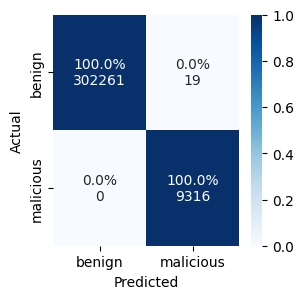

Training time for on all data: 27.3198

Evaluating model: support_vector_machine_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,23.157431,16.529007,0.999062,1.0,0.998125,0.999944,0.999942,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241810, 14], [0, 7452]]",4.089820,0.998928,1.0,0.997859,0.999936,0.999934,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60452, 4], [0, 1864]]"
1,25.661859,16.651424,0.998995,1.0,0.997991,0.999940,0.999938,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241809, 15], [0, 7453]]",4.126480,0.998660,1.0,0.997323,0.999920,0.999917,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60451, 5], [0, 1863]]"
2,19.129111,14.425225,0.999330,1.0,0.998660,0.999960,0.999959,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241814, 10], [0, 7453]]",3.627020,0.998660,1.0,0.997323,0.999920,0.999917,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60451, 5], [0, 1863]]"
3,34.636861,21.073414,0.998861,1.0,0.997724,0.999932,0.999930,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241807, 17], [0, 7453]]",3.711241,0.999195,1.0,0.998392,0.999952,0.999950,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60453, 3], [0, 1863]]"
4,33.062757,22.243100,0.998861,1.0,0.997724,0.999932,0.999930,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241807, 17], [0, 7453]]",3.854526,0.999464,1.0,0.998928,0.999968,0.999967,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60454, 2], [0, 1863]]"
mean,27.129604,18.184434,0.999021,1.0,0.998045,0.999941,0.999940,NaN,249276.800000,NaN,3.881817,0.998981,1.0,0.997965,0.999939,0.999937,NaN,62319.200000,NaN
std,6.585999,3.318177,0.000193,0.0,0.000385,0.000012,0.000012,NaN,0.447214,NaN,0.222423,0.000349,0.0,0.000697,0.000021,0.000022,NaN,0.447214,NaN


Aggregated test confusion matrix:


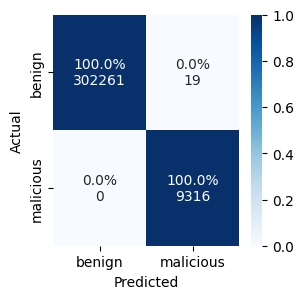

Training time for on all data: 25.4091



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in available_models:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate_stratified_group(ml_pipeline, X, y, groups, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    # if model_name == 'one_rule':
    #     # Prevent information leakage by using the best rule from the cross evaluation
    #     models[model_name] = ml_pipeline.fit(X, y, clf__feature_idx=69)
    # else:
    models[model_name] = ml_pipeline.fit(X, y)
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

Evaluating model: hist_gradient_boosting


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,22.598190,2.435983,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7452}",249276.000000,"[[241824, 0], [0, 7452]]",0.376297,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 60456, 1.0: 1864}",62320.000000,"[[60456, 0], [0, 1864]]"
1,15.554734,2.264047,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.681908,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
2,21.601626,2.005549,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.465591,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
3,23.888742,1.626988,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.159879,0.999732,0.999463,1.0,0.999984,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [1, 1862]]"
4,22.754158,1.754338,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 7453}",249277.000000,"[[241824, 0], [0, 7453]]",0.358849,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 60456, 1.0: 1863}",62319.000000,"[[60456, 0], [0, 1863]]"
mean,21.279490,2.017381,1.0,1.0,1.0,1.0,1.0,NaN,249276.800000,NaN,0.408505,0.999946,0.999893,1.0,0.999997,1.0,NaN,62319.200000,NaN
std,3.301455,0.338308,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.189292,0.000120,0.000240,0.0,0.000007,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


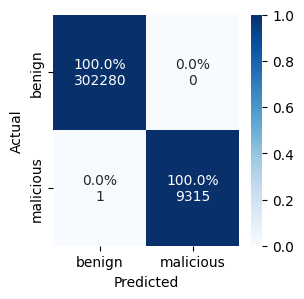

Training time for on all data: 8.5073



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in ['hist_gradient_boosting']:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate_stratified_group(ml_pipeline, X, y, groups, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    # if model_name == 'one_rule':
    #     # Prevent information leakage by using the best rule from the cross evaluation
    #     models[model_name] = ml_pipeline.fit(X, y, clf__feature_idx=69)
    # else:
    models[model_name] = ml_pipeline.fit(X, y)
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

# Evaluate the Generalisation Strength

In [8]:
for model_name in available_models:
    print("Evaluating model: {}".format(model_name))
    with open(f"{result_dir}/{model_name}.p", "rb") as f:
        ml_pipeline = pickle.load(f)
        results = []
        
        # Original malicious
        start_time = time.time()
        y_pred = ml_pipeline.predict(X_mal)
        end_time = time.time() - start_time
        result = {
            'scenario': 'Original-malicious',
            'pred_time': end_time,
            'pred_benign': np.sum(y_pred == 0),
            'pred_attack': np.sum(y_pred == 1)
        }
        results.append(result)

        # Left out ConCap scenarios
        for scenario in groups_test.unique():
            X_scenario, y_scenario = X_adv_test[groups_test == scenario], y_adv_test[groups_test == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            result = {
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1)
            }
            results.append(result)
        display(pd.DataFrame(results))

Evaluating model: decision_tree


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.004010,58,2903
1,patator-ssh-cic-t5,0.002531,2,3398
2,patator-ssh-cic-t5-p-rl1,0.001544,85,510
3,patator-ssh-cic-t5-p,0.001480,85,510
4,patator-ssh-cic-ubuntu22,0.001621,170,510
5,patator-ssh-cic-ubuntu20,0.001438,170,510
6,patator-ssh-cic-d10-l5-c0-dup0,0.001426,93,587
7,patator-ssh-cic-d100-l5-c0-dup0,0.001658,70,610
8,patator-ssh-cic-d100-l5-c5-dup0,0.001533,201,479
9,patator-ssh-cic-d25-l0-c5-dup0,0.001432,73,607


Evaluating model: decision_tree_vt


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.002514,65,2896
1,patator-ssh-cic-t5,0.002487,0,3400
2,patator-ssh-cic-t5-p-rl1,0.001522,85,510
3,patator-ssh-cic-t5-p,0.001533,85,510
4,patator-ssh-cic-ubuntu22,0.001514,170,510
5,patator-ssh-cic-ubuntu20,0.001441,170,510
6,patator-ssh-cic-d10-l5-c0-dup0,0.001439,91,589
7,patator-ssh-cic-d100-l5-c0-dup0,0.001426,45,635
8,patator-ssh-cic-d100-l5-c5-dup0,0.001671,140,540
9,patator-ssh-cic-d25-l0-c5-dup0,0.001519,76,604


Evaluating model: logistic_regression


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.003128,46,2915
1,patator-ssh-cic-t5,0.003026,0,3400
2,patator-ssh-cic-t5-p-rl1,0.001720,0,595
3,patator-ssh-cic-t5-p,0.001719,0,595
4,patator-ssh-cic-ubuntu22,0.001692,0,680
5,patator-ssh-cic-ubuntu20,0.001670,0,680
6,patator-ssh-cic-d10-l5-c0-dup0,0.001558,9,671
7,patator-ssh-cic-d100-l5-c0-dup0,0.001654,8,672
8,patator-ssh-cic-d100-l5-c5-dup0,0.001657,46,634
9,patator-ssh-cic-d25-l0-c5-dup0,0.001597,6,674


... (14 outputs left out)

Evaluating model: support_vector_machine


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.241777,21,2940
1,patator-ssh-cic-t5,0.214415,0,3400
2,patator-ssh-cic-t5-p-rl1,0.037571,0,595
3,patator-ssh-cic-t5-p,0.037072,0,595
4,patator-ssh-cic-ubuntu22,0.044892,0,680
5,patator-ssh-cic-ubuntu20,0.042846,0,680
6,patator-ssh-cic-d10-l5-c0-dup0,0.042998,0,680
7,patator-ssh-cic-d100-l5-c0-dup0,0.042652,0,680
8,patator-ssh-cic-d100-l5-c5-dup0,0.042897,0,680
9,patator-ssh-cic-d25-l0-c5-dup0,0.042381,0,680


Evaluating model: support_vector_machine_vt


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.181792,21,2940
1,patator-ssh-cic-t5,0.204794,0,3400
2,patator-ssh-cic-t5-p-rl1,0.035799,0,595
3,patator-ssh-cic-t5-p,0.035903,0,595
4,patator-ssh-cic-ubuntu22,0.040844,0,680
5,patator-ssh-cic-ubuntu20,0.040606,0,680
6,patator-ssh-cic-d10-l5-c0-dup0,0.045831,0,680
7,patator-ssh-cic-d100-l5-c0-dup0,0.045552,0,680
8,patator-ssh-cic-d100-l5-c5-dup0,0.040975,0,680
9,patator-ssh-cic-d25-l0-c5-dup0,0.040850,0,680


In [8]:
for model_name in ['hist_gradient_boosting']:
    print("Evaluating model: {}".format(model_name))
    with open(f"{result_dir}/{model_name}.p", "rb") as f:
        ml_pipeline = pickle.load(f)
        results = []
        
        # Original malicious
        start_time = time.time()
        y_pred = ml_pipeline.predict(X_mal)
        end_time = time.time() - start_time
        result = {
            'scenario': 'Original-malicious',
            'pred_time': end_time,
            'pred_benign': np.sum(y_pred == 0),
            'pred_attack': np.sum(y_pred == 1)
        }
        results.append(result)

        # Left out ConCap scenarios
        for scenario in groups_test.unique():
            X_scenario, y_scenario = X_adv_test[groups_test == scenario], y_adv_test[groups_test == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            result = {
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1)
            }
            results.append(result)
        display(pd.DataFrame(results))

Evaluating model: hist_gradient_boosting


,scenario,pred_time,pred_benign,pred_attack
0,Original-malicious,0.068186,24,2937
1,patator-ssh-cic-t5,0.079516,0,3400
2,patator-ssh-cic-t5-p-rl1,0.045256,0,595
3,patator-ssh-cic-t5-p,0.040184,0,595
4,patator-ssh-cic-ubuntu22,0.005783,680,0
5,patator-ssh-cic-ubuntu20,0.005579,680,0
6,patator-ssh-cic-d10-l5-c0-dup0,0.021450,11,669
7,patator-ssh-cic-d100-l5-c0-dup0,0.014329,18,662
8,patator-ssh-cic-d100-l5-c5-dup0,0.020666,43,637
9,patator-ssh-cic-d25-l0-c5-dup0,0.011015,7,673
